## 0. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1. Imports and configuration

In [ ]:
from pathlib import Path
import os, json, zipfile, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DRIVE = Path("/content/drive/MyDrive")
PROJECT = DRIVE / "TrashNet_ML_Cycle"
DATA = PROJECT / "data"
RAW_ZIP = PROJECT / "data" / "trashnet_raw.zip"
EXTRACTED = DATA / "extracted"
TRAIN_DIR, TEST_DIR = DATA / "train", DATA / "test"
VAL_DIR = DATA / "validation"
MODELS, SRC, REPORTS = PROJECT / "models", PROJECT / "src", PROJECT / "reports"
for folder in [DATA, EXTRACTED, TRAIN_DIR, TEST_DIR, MODELS, SRC, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_FRACTION = 0.20

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Expected ZIP:", RAW_ZIP)
if not RAW_ZIP.exists():
    raise FileNotFoundError(f"Upload trashnet_raw.zip to Google Drive > MyDrive > data. Expected: {RAW_ZIP}")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Expected ZIP: /content/drive/MyDrive/TrashNet_ML_Cycle/data/trashnet_raw.zip


## Phase 1 — Data acquisition

### 1.1 Extract archive and locate class folders

In [ ]:
def extract_archive(zip_path: Path, destination: Path) -> None:
    """Extract the raw dataset archive into the persistent project data directory."""
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(destination)

def find_class_root(root: Path, class_names: list[str]) -> Path:
    """Find a directory whose immediate subfolders include all expected class names."""
    for candidate in [root] + [p for p in root.rglob("*") if p.is_dir()]:
        child_names = {p.name.lower() for p in candidate.iterdir() if p.is_dir()}
        if set(class_names).issubset(child_names):
            return candidate
    raise FileNotFoundError("Could not find all six class folders. Inspect EXTRACTED and set IMAGE_ROOT manually.")

extract_archive(RAW_ZIP, EXTRACTED)
IMAGE_ROOT = find_class_root(EXTRACTED, CLASSES)
print("Image root:", IMAGE_ROOT)
for name in CLASSES:
    print(name, sum(1 for p in (IMAGE_ROOT/name).rglob("*") if p.is_file()))

Image root: /content/drive/MyDrive/TrashNet_ML_Cycle/data/extracted/dataset-resized
cardboard 403
glass 501
metal 410
paper 594
plastic 482
trash 137


### 1.2 Validate files, dimensions, and corrupted images

In [ ]:
def inspect_image(path: Path) -> dict:
    """Verify an image file and return dimensions, or report it as unreadable."""
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            width, height = im.size
        return {"readable": True, "width": width, "height": height, "error": ""}
    except Exception as exc:
        return {"readable": False, "width": None, "height": None, "error": str(exc)}

records = []
for class_name in CLASSES:
    for path in (IMAGE_ROOT/class_name).rglob("*"):
        if path.is_file() and path.suffix.lower() in EXTENSIONS:
            records.append({"filepath": str(path), "label": class_name, **inspect_image(path)})

all_df = pd.DataFrame(records)
if all_df.empty:
    raise ValueError("No image files found. Check the archive structure.")
corrupt_df = all_df[~all_df.readable].copy()
df = all_df[all_df.readable].copy().reset_index(drop=True)
print("Candidate files:", len(all_df), "| Readable:", len(df), "| Corrupted:", len(corrupt_df))
if len(corrupt_df):
    corrupt_df.to_csv(REPORTS/"corrupted_images.csv", index=False)
display(df[["width", "height"]].describe())

Candidate files: 2527 | Readable: 2527 | Corrupted: 0


,width,height
count,2527.0,2527.0
mean,512.0,384.0
std,0.0,0.0
min,512.0,384.0
25%,512.0,384.0
50%,512.0,384.0
75%,512.0,384.0
max,512.0,384.0


### 1.3 Stratified 80/20 train/test split and CSV manifests

The held-out test set is created once here. The training partition is later divided into fitting and validation subsets in Phase 3.

In [ ]:
def stratified_split(dataframe: pd.DataFrame, test_size: float = 0.20):
    """Split readable image records into stratified training and test partitions."""
    return train_test_split(
        dataframe,
        test_size=test_size,
        random_state=SEED,
        stratify=dataframe["label"]
    )


train_df, test_df = stratified_split(df, test_size=0.20)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


def copy_split_images(dataframe: pd.DataFrame, destination: Path) -> pd.DataFrame:
    """Copy split images into class-specific folders and return records with persistent copied paths."""
    copied_records = []

    for row in dataframe.itertuples(index=False):
        class_folder = destination / row.label
        class_folder.mkdir(parents=True, exist_ok=True)

        source = Path(row.filepath)
        target = class_folder / source.name

        if target.exists():
            target = class_folder / f"{source.stem}_{len(copied_records)}{source.suffix}"

        shutil.copy2(source, target)

        copied_records.append({
            "filepath": str(target),
            "label": row.label,
            "width": row.width,
            "height": row.height,
            "readable": True
        })

    return pd.DataFrame(copied_records)


train_df = copy_split_images(train_df, TRAIN_DIR)
test_df = copy_split_images(test_df, TEST_DIR)

train_df[["filepath", "label"]].to_csv(DATA / "train.csv", index=False)
test_df[["filepath", "label"]].to_csv(DATA / "test.csv", index=False)

print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(df):.1%})")
print("Train class folders:", sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir()))
print("Test class folders:", sorted(p.name for p in TEST_DIR.iterdir() if p.is_dir()))

Train: 2021 (80.0%)
Test: 506 (20.0%)
Train class folders: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Test class folders: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


### 1.4 Class counts and imbalance

In [ ]:
def class_count_summary(dataframe: pd.DataFrame, split_name: str) -> pd.DataFrame:
    """Calculate image counts and percentages for each class in a dataset split."""
    counts = dataframe.label.value_counts().reindex(CLASSES, fill_value=0)
    return pd.DataFrame({"class": counts.index, "count": counts.values,
                         "percentage": (counts.values/len(dataframe)*100).round(2), "split": split_name})

train_counts = class_count_summary(train_df, "train")
test_counts = class_count_summary(test_df, "test")
display(pd.concat([train_counts, test_counts], ignore_index=True))
imbalance_ratio = train_counts["count"].max()/train_counts["count"].min()
print(f"Training max/min class count ratio: {imbalance_ratio:.2f}")

,class,count,percentage,split
0,cardboard,322,15.93,train
1,glass,401,19.84,train
2,metal,328,16.23,train
3,paper,475,23.50,train
4,plastic,385,19.05,train
5,trash,110,5.44,train
6,cardboard,81,16.01,test
7,glass,100,19.76,test
8,metal,82,16.21,test
9,paper,119,23.52,test


Training max/min class count ratio: 4.32


## Phase 2 — Exploratory data analysis

### Visualization 1: Class distribution

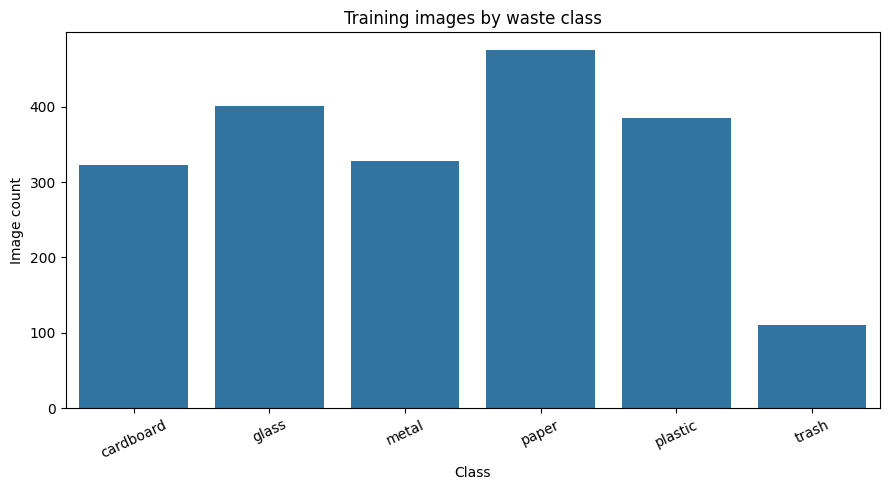

Interpretation: paper is largest (475); trash is smallest (110). Max/min ratio=4.32. Discuss the observed imbalance and whether class weights are appropriate.


In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(data=train_counts, x="class", y="count")
plt.title("Training images by waste class"); plt.xlabel("Class"); plt.ylabel("Image count")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()
largest, smallest = train_counts.loc[train_counts["count"].idxmax()], train_counts.loc[train_counts["count"].idxmin()]
print(f"Interpretation: {largest['class']} is largest ({largest['count']}); {smallest['class']} is smallest ({smallest['count']}). Max/min ratio={imbalance_ratio:.2f}. Discuss the observed imbalance and whether class weights are appropriate.")

### Visualization 2: Sample image grid

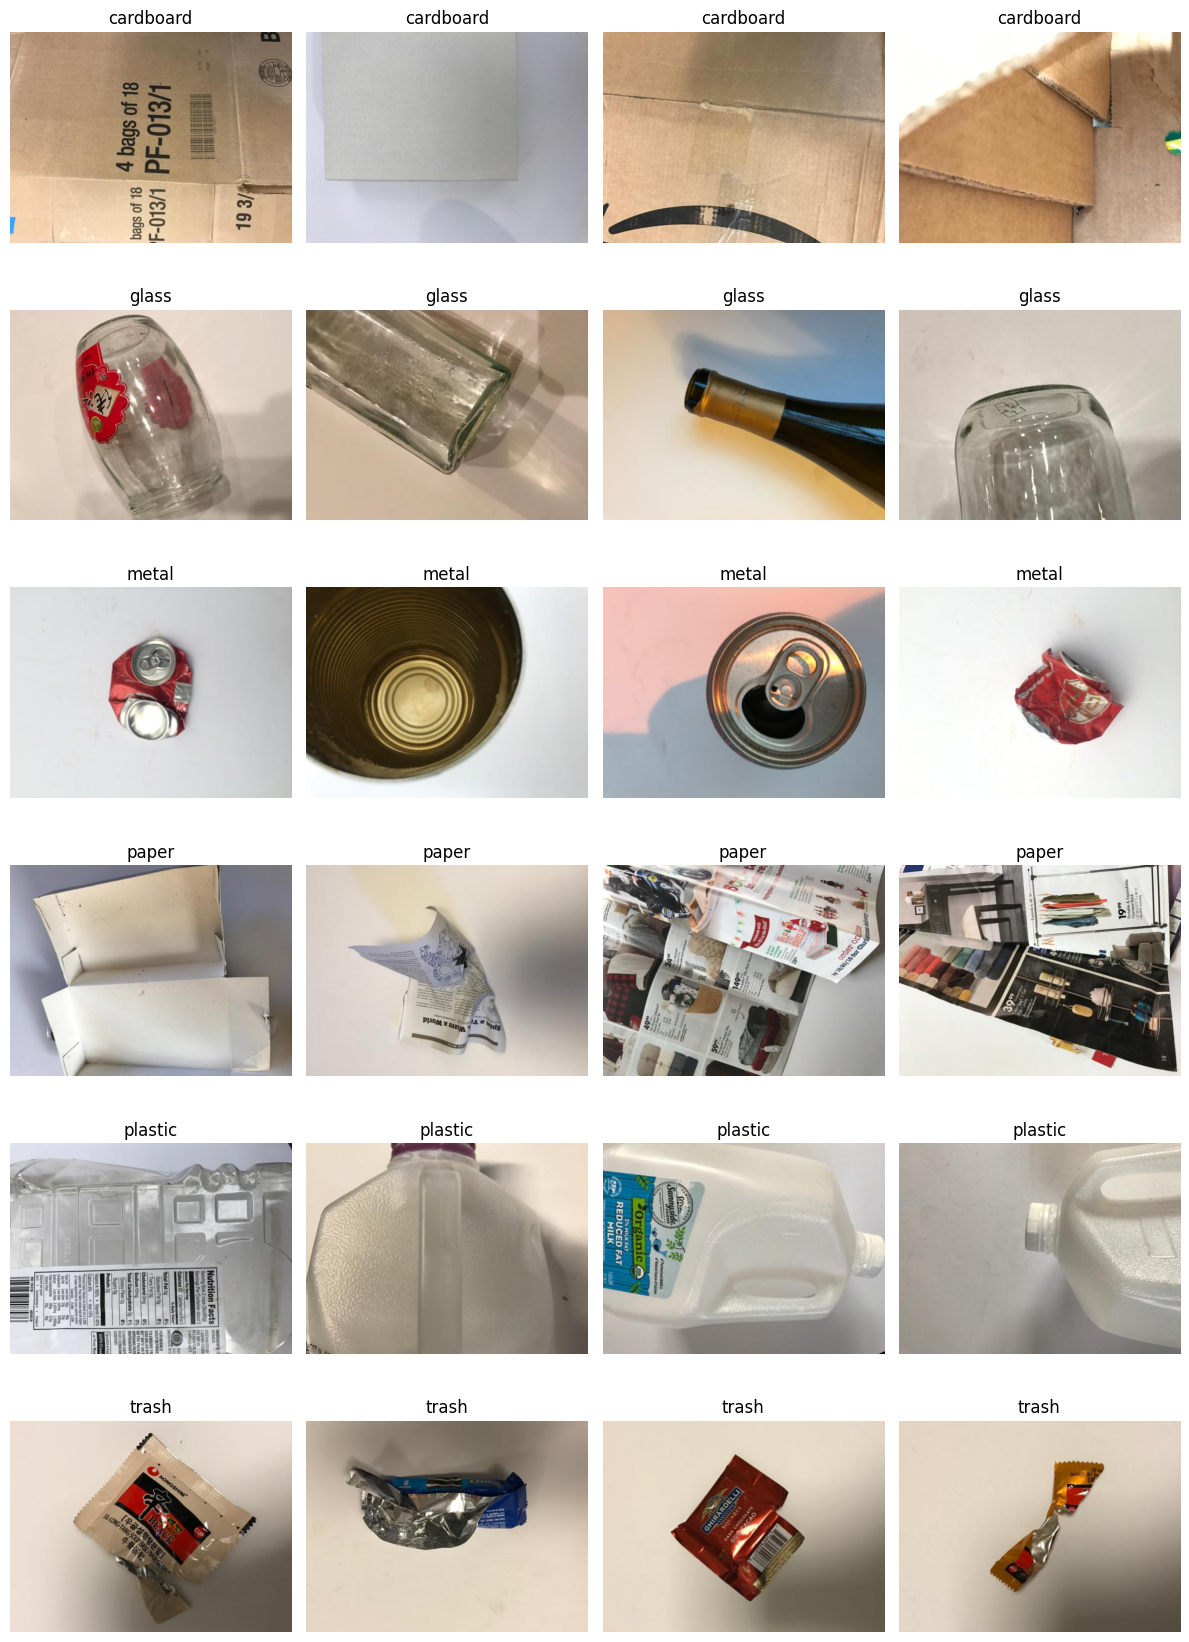

Interpretation: describe visible within-class similarities, differences between classes, backgrounds, lighting, and any visually ambiguous categories. Base this on the grid.


In [ ]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12,17))
for row, name in enumerate(CLASSES):
    samples = train_df[train_df.label == name].sample(n=min(4, (train_df.label == name).sum()), random_state=SEED)
    for col in range(4):
        axes[row,col].axis("off")
        if col < len(samples):
            with Image.open(samples.iloc[col].filepath) as im:
                axes[row,col].imshow(im.convert("RGB"))
            axes[row,col].set_title(name)
plt.tight_layout(); plt.show()
print("Interpretation: describe visible within-class similarities, differences between classes, backgrounds, lighting, and any visually ambiguous categories. Base this on the grid.")

### Visualization 3: Colour and brightness

,red,green,blue,brightness
label,,,,
cardboard,0.667,0.582,0.501,0.583
glass,0.693,0.670,0.641,0.668
metal,0.646,0.615,0.593,0.618
paper,0.674,0.643,0.607,0.641
plastic,0.670,0.666,0.662,0.666
trash,0.702,0.652,0.585,0.646


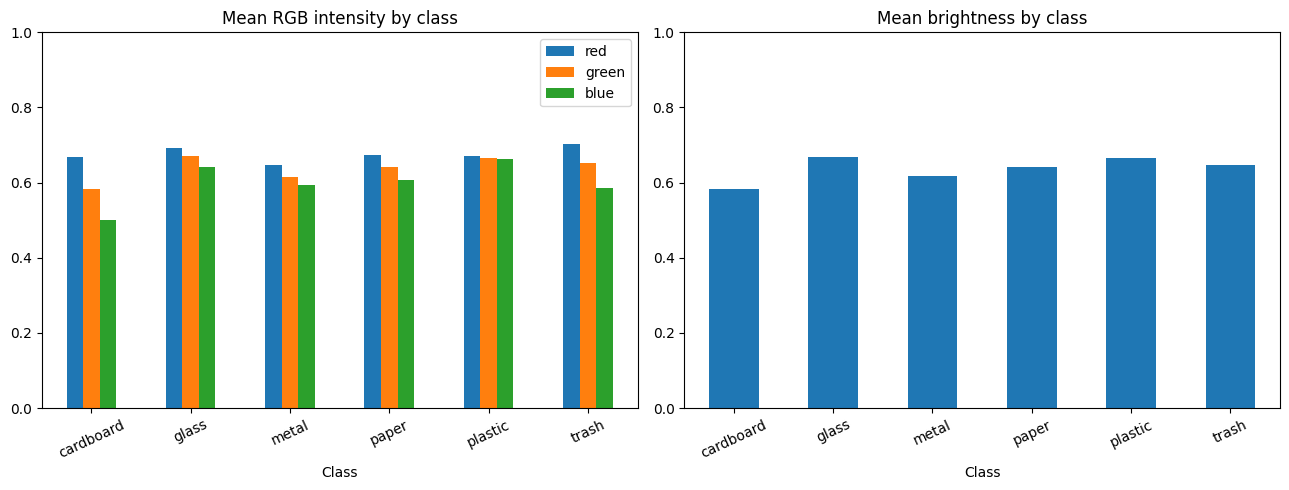

Interpretation: glass has highest mean brightness (0.668); cardboard has lowest (0.583). Consider whether lighting or background could act as a shortcut.


In [ ]:
def image_colour_stats(path: str) -> dict:
    """Calculate normalized mean red, green, blue, and overall brightness for an image."""
    with Image.open(path) as im:
        arr = np.asarray(im.convert("RGB").resize((128,128)), dtype=np.float32)/255.0
    return {"red": arr[:,:,0].mean(), "green": arr[:,:,1].mean(),
            "blue": arr[:,:,2].mean(), "brightness": arr.mean()}

colour_df = pd.DataFrame([{"label": r.label, **image_colour_stats(r.filepath)}
                          for r in train_df.itertuples(index=False)])
colour_summary = colour_df.groupby("label")[["red","green","blue","brightness"]].mean().reindex(CLASSES)
display(colour_summary.round(3))
fig, axes = plt.subplots(1,2,figsize=(13,5))
colour_summary[["red","green","blue"]].plot(kind="bar", ylim=(0,1), ax=axes[0], title="Mean RGB intensity by class")
colour_summary["brightness"].plot(kind="bar", ylim=(0,1), ax=axes[1], title="Mean brightness by class")
for ax in axes: ax.set_xlabel("Class"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()
brightest, darkest = colour_summary.brightness.idxmax(), colour_summary.brightness.idxmin()
print(f"Interpretation: {brightest} has highest mean brightness ({colour_summary.loc[brightest,'brightness']:.3f}); {darkest} has lowest ({colour_summary.loc[darkest,'brightness']:.3f}). Consider whether lighting or background could act as a shortcut.")

### Visualization 4: Original image dimensions

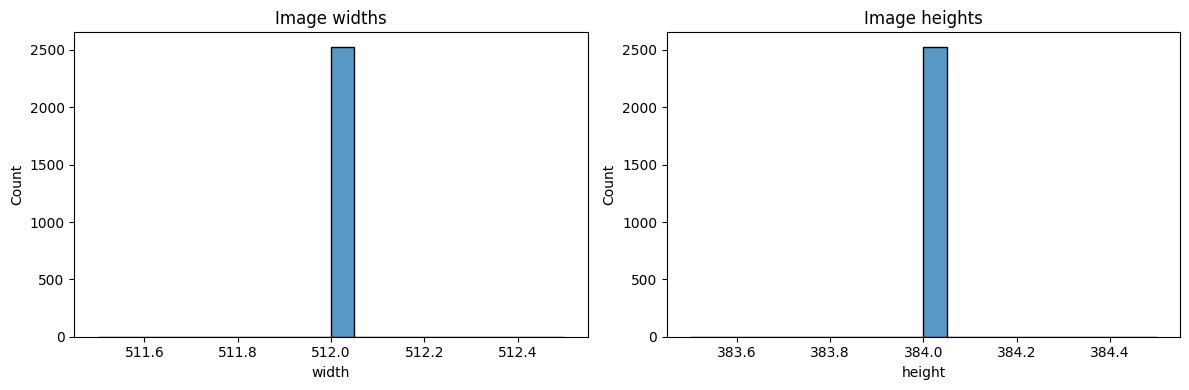

Interpretation: widths range 512–512 px; heights range 384–384 px. Resizing provides a consistent 224×224 input shape.


In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(df.width, bins=20, ax=axes[0]); axes[0].set_title("Image widths")
sns.histplot(df.height, bins=20, ax=axes[1]); axes[1].set_title("Image heights")
plt.tight_layout(); plt.show()
print(f"Interpretation: widths range {df.width.min()}–{df.width.max()} px; heights range {df.height.min()}–{df.height.max()} px. Resizing provides a consistent 224×224 input shape.")

## Phase 3 — Preprocessing (`src/preprocessing.py`)

### 3.1 Encode labels and persist class order

In [ ]:
encoder = LabelEncoder().fit(CLASSES)
class_names = encoder.classes_.tolist()
class_to_index = {name: i for i, name in enumerate(class_names)}
with open(MODELS/"class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)
print("Saved class order:", class_names)

Saved class order: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


### 3.2 Validation split, preprocessing and TensorFlow pipelines

In [ ]:
fit_df, validation_df = train_test_split(
    train_df, test_size=0.20, random_state=SEED, stratify=train_df.label
)
fit_df = fit_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)


def decode_resize_scale(path, label):
    """Decode an RGB image, resize it to 224x224, and scale pixels to [0, 1]."""
    image = tf.io.decode_image(
        tf.io.read_file(path), channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    return tf.cast(image, tf.float32) / 255.0, label


augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="train_augmentation")


def make_dataset(frame, training=False):
    """Create a batched dataset; apply standard augmentation only during training."""
    labels = frame.label.map(class_to_index).to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices(
        (frame.filepath.to_numpy(), labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame), seed=SEED, reshuffle_each_iteration=True
        )

    ds = ds.map(decode_resize_scale, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.map(
            lambda x, y: (augmentation(x, training=True), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


fit_ds = make_dataset(fit_df, training=True)
fit_plain_ds = make_dataset(fit_df, training=False)
validation_ds = make_dataset(validation_df)
test_ds = make_dataset(test_df)

weights = compute_class_weight(
    "balanced",
    classes=np.arange(len(CLASSES)),
    y=fit_df.label.map(class_to_index).to_numpy()
)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(weights)}

print("Class weights:", CLASS_WEIGHTS)
print("Fit/validation/test:", len(fit_df), len(validation_df), len(test_df))


trash_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.12),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.08, width_factor=0.08)
], name="trash_targeted_augmentation")

TRASH_INDEX = class_to_index["trash"]


def augment_by_class(image, label):
    """Apply standard augmentation to every image and extra augmentation to trash images."""
    image = augmentation(image, training=True)
    image = tf.cond(
        tf.equal(label, TRASH_INDEX),
        lambda: trash_augmentation(image, training=True),
        lambda: image
    )
    return image, label


def make_targeted_dataset(frame, training=False):
    """Create a dataset with additional on-the-fly augmentation for trash images."""
    labels = frame.label.map(class_to_index).to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices(
        (frame.filepath.to_numpy(), labels)
    )

    if training:
        ds = ds.shuffle(
            len(frame), seed=SEED, reshuffle_each_iteration=True
        )

    ds = ds.map(decode_resize_scale, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.map(
            augment_by_class,
            num_parallel_calls=tf.data.AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


fit_ds_4 = make_targeted_dataset(fit_df, training=True)
validation_ds_4 = make_targeted_dataset(validation_df, training=False)

Class weights: {0: 1.0479896238651103, 1: 0.8390446521287642, 2: 1.0279898218829517, 3: 0.7087719298245614, 4: 0.8744588744588745, 5: 3.0606060606060606}
Fit/validation/test: 1616 405 506


### 3.3 Save reusable preprocessing module

In [ ]:
preprocessing_code = r'''
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.utils.class_weight import compute_class_weight

IMAGE_SIZE = (224, 224)

def load_class_names(path):
    """Load the ordered class names used by the model output indices."""
    with open(path, "r") as file:
        return json.load(file)

def decode_resize_scale(path, label):
    """Decode RGB image data, resize to 224x224, and normalize pixels to [0, 1]."""
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    return tf.cast(image, tf.float32) / 255.0, label

def calculate_class_weights(integer_labels, class_count):
    """Calculate balanced class weights from integer labels in the training partition."""
    values = compute_class_weight("balanced", classes=np.arange(class_count),
                                  y=np.asarray(integer_labels))
    return {i: float(value) for i, value in enumerate(values)}

def create_dataset(dataframe, class_to_index, training=False, batch_size=32):
    """Build a TensorFlow dataset and apply augmentation only when training is True."""
    augmentation = keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(0.08),
        keras.layers.RandomZoom(0.10)
    ])
    labels = dataframe.label.map(class_to_index).to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((dataframe.filepath.to_numpy(), labels))
    if training:
        dataset = dataset.shuffle(len(dataframe), reshuffle_each_iteration=True)
    dataset = dataset.map(decode_resize_scale, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        dataset = dataset.map(lambda x,y: (augmentation(x, training=True), y),
                              num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
'''
(SRC/"preprocessing.py").write_text(preprocessing_code)
print("Created", SRC/"preprocessing.py")

Created /content/drive/MyDrive/TrashNet_ML_Cycle/src/preprocessing.py


## Phase 4 — Model development (`src/model.py`)

In [ ]:
def build_model(dropout=0.3, l2_strength=1e-4):
    """Build a MobileNetV2 classifier for six classes and return model plus backbone."""
    backbone = keras.applications.MobileNetV2(
        input_shape=(224,224,3), include_top=False, weights="imagenet"
    )
    backbone.trainable = False
    inputs = keras.Input((224,224,3))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(len(CLASSES), activation="softmax",
                           kernel_regularizer=regularizers.l2(l2_strength))(x)
    return keras.Model(inputs, outputs), backbone

def compile_model(model, learning_rate):
    """Compile the classifier with Adam and sparse categorical cross-entropy."""
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def training_callbacks(name):
    """Create best-checkpoint, early-stopping, and learning-rate-reduction callbacks."""
    return [
        keras.callbacks.ModelCheckpoint(str(MODELS/f"{name}_best.keras"),
                                        monitor="val_loss", save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2,
                                          patience=2, min_lr=1e-7)
    ]

def fine_tune_backbone(backbone, unfreeze_last=30):
    """Unfreeze only the final backbone layers and keep BatchNormalization frozen."""
    backbone.trainable = True
    for layer in backbone.layers[:-unfreeze_last]: layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization): layer.trainable = False

### 4.2 Experiment 1 — Frozen MobileNetV2 baseline

In [ ]:
model_1, backbone_1 = build_model(dropout=0.0, l2_strength=0.0)
compile_model(model_1, 1e-3)
history_1 = model_1.fit(fit_plain_ds, validation_data=validation_ds, epochs=8,
                        callbacks=training_callbacks("experiment_1"), verbose=1)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 69s 845ms/step - accuracy: 0.5823 - loss: 1.1167 - val_accuracy: 0.7481 - val_loss: 0.7032 - learning_rate: 0.0010
Epoch 2/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 25s 111ms/step - accuracy: 0.7921 - loss: 0.5852 - val_accuracy: 0.8025 - val_loss: 0.5698 - learning_rate: 0.0010
Epoch 3/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 12s 141ms/step - accuracy: 0.8515 - loss: 0.4563 - val_accuracy: 0.8173 - val_loss: 0.5184 - learning_rate: 0.0010
Epoch 4/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 105ms/step - accuracy: 0.8787 - loss: 0.3777 - val_accuracy: 0.8198 - val_loss: 0.4898 - learning_rate: 0.0010
Epoch 5/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 140ms/step - accuracy: 0.9078 - loss: 0.3218 - val_accuracy: 0.8370 - val_loss: 0.4712 - learning_rate: 0.0010
Epoch 6/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - accuracy: 0.9251 - loss: 0.2789 - val_accuracy: 0.8395 - val_loss: 0.4579 - learning_rate: 0.0010
Epoch 7/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 14

### 4.3 Experiment 2 — Fine-tuned MobileNetV2

In [ ]:
model_2, backbone_2 = build_model(dropout=0.2, l2_strength=1e-5)
compile_model(model_2, 1e-3)
history_2a = model_2.fit(fit_plain_ds, validation_data=validation_ds, epochs=6,
                         callbacks=training_callbacks("experiment_2_stage1"), verbose=1)
fine_tune_backbone(backbone_2, unfreeze_last=30)
compile_model(model_2, 1e-5)
history_2b = model_2.fit(fit_ds, validation_data=validation_ds, epochs=6,
                         callbacks=training_callbacks("experiment_2"), verbose=1)

Epoch 1/6
51/51 ━━━━━━━━━━━━━━━━━━━━ 24s 330ms/step - accuracy: 0.5179 - loss: 1.2565 - val_accuracy: 0.7704 - val_loss: 0.6830 - learning_rate: 0.0010
Epoch 2/6
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.7735 - loss: 0.6617 - val_accuracy: 0.7975 - val_loss: 0.5542 - learning_rate: 0.0010
Epoch 3/6
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 99ms/step - accuracy: 0.8168 - loss: 0.5287 - val_accuracy: 0.8198 - val_loss: 0.5041 - learning_rate: 0.0010
Epoch 4/6
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 135ms/step - accuracy: 0.8354 - loss: 0.4578 - val_accuracy: 0.8370 - val_loss: 0.4739 - learning_rate: 0.0010
Epoch 5/6
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - accuracy: 0.8731 - loss: 0.3785 - val_accuracy: 0.8543 - val_loss: 0.4515 - learning_rate: 0.0010
Epoch 6/6
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 139ms/step - accuracy: 0.8843 - loss: 0.3391 - val_accuracy: 0.8568 - val_loss: 0.4392 - learning_rate: 0.0010
Epoch 1/6
51/51 ━━━━━━━━━━━━━━━━━━━━ 48s 668ms/step - accuracy: 0.8354 - loss: 0.4404 - val_ac

### 4.4 Experiment 3 — Fine-tuning + augmentation + dropout + L2 + class weights

In [ ]:
model_3, backbone_3 = build_model(dropout=0.4, l2_strength=1e-4)
compile_model(model_3, 1e-3)
history_3a = model_3.fit(fit_ds, validation_data=validation_ds, epochs=8,
                         class_weight=CLASS_WEIGHTS,
                         callbacks=training_callbacks("experiment_3_stage1"), verbose=1)
fine_tune_backbone(backbone_3, unfreeze_last=30)
compile_model(model_3, 1e-5)
history_3b = model_3.fit(fit_ds, validation_data=validation_ds, epochs=8,
                         class_weight=CLASS_WEIGHTS,
                         callbacks=training_callbacks("experiment_3"), verbose=1)

Epoch 1/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 39s 560ms/step - accuracy: 0.3948 - loss: 1.6027 - val_accuracy: 0.7111 - val_loss: 0.8284 - learning_rate: 0.0010
Epoch 2/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 21s 404ms/step - accuracy: 0.6448 - loss: 0.9650 - val_accuracy: 0.7654 - val_loss: 0.6614 - learning_rate: 0.0010
Epoch 3/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 22s 426ms/step - accuracy: 0.7147 - loss: 0.7701 - val_accuracy: 0.7951 - val_loss: 0.5736 - learning_rate: 0.0010
Epoch 4/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 398ms/step - accuracy: 0.7382 - loss: 0.6827 - val_accuracy: 0.8123 - val_loss: 0.5572 - learning_rate: 0.0010
Epoch 5/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 22s 441ms/step - accuracy: 0.7667 - loss: 0.6268 - val_accuracy: 0.8198 - val_loss: 0.5479 - learning_rate: 0.0010
Epoch 6/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 392ms/step - accuracy: 0.7983 - loss: 0.5678 - val_accuracy: 0.8198 - val_loss: 0.5057 - learning_rate: 0.0010
Epoch 7/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 21s 406ms/step - accuracy: 0.8014 - loss: 0.5305 - 

In [ ]:
model_4, backbone_4 = build_model(dropout=0.4, l2_strength=1e-4)

compile_model(model_4, 1e-3)
history_4a = model_4.fit(
    fit_ds_4,
    validation_data=validation_ds_4,
    epochs=8,
    class_weight=CLASS_WEIGHTS,
    callbacks=training_callbacks("experiment_4_stage1"),
    verbose=1
)

fine_tune_backbone(backbone_4, unfreeze_last=30)
compile_model(model_4, 1e-5)
history_4b = model_4.fit(
    fit_ds_4,
    validation_data=validation_ds_4,
    epochs=8,
    class_weight=CLASS_WEIGHTS,
    callbacks=training_callbacks("experiment_4"),
    verbose=1
)

Epoch 1/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 40s 593ms/step - accuracy: 0.4109 - loss: 1.6622 - val_accuracy: 0.6988 - val_loss: 0.8194 - learning_rate: 0.0010
Epoch 2/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 24s 471ms/step - accuracy: 0.6417 - loss: 0.9546 - val_accuracy: 0.7481 - val_loss: 0.6464 - learning_rate: 0.0010
Epoch 3/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 40s 461ms/step - accuracy: 0.7234 - loss: 0.7477 - val_accuracy: 0.7926 - val_loss: 0.5732 - learning_rate: 0.0010
Epoch 4/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 41s 470ms/step - accuracy: 0.7642 - loss: 0.6431 - val_accuracy: 0.8099 - val_loss: 0.5359 - learning_rate: 0.0010
Epoch 5/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 21s 417ms/step - accuracy: 0.7834 - loss: 0.5810 - val_accuracy: 0.7926 - val_loss: 0.5467 - learning_rate: 0.0010
Epoch 6/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 23s 451ms/step - accuracy: 0.7976 - loss: 0.5580 - val_accuracy: 0.8123 - val_loss: 0.5018 - learning_rate: 0.0010
Epoch 7/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 23s 459ms/step - accuracy: 0.8162 - loss: 0.4943 - 

### 4.6 Compare experiments on validation data

In [ ]:
def evaluate_metrics(model, dataset):
    """Return accuracy, macro precision, macro recall, macro F1, and predictions."""
    y_true = np.concatenate([y.numpy() for _,y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)
    return {
        "accuracy": accuracy_score(y_true,y_pred),
        "precision": precision_score(y_true,y_pred,average="macro",zero_division=0),
        "recall": recall_score(y_true,y_pred,average="macro",zero_division=0),
        "f1": f1_score(y_true,y_pred,average="macro",zero_division=0),
        "y_true": y_true, "y_pred": y_pred
    }

models = {
    "Experiment 1 — Frozen baseline": model_1,
    "Experiment 2 — Fine-tuned": model_2,
    "Experiment 3 — Regularized + class weights": model_3,
    "Experiment 4 — Targeted trash augmentation": model_4
}
val_results = {name: evaluate_metrics(model, validation_ds) for name,model in models.items()}
comparison = pd.DataFrame([
    {"experiment": name, "accuracy": result["accuracy"],
     "macro_precision": result["precision"], "macro_recall": result["recall"],
     "macro_f1": result["f1"]}
    for name,result in val_results.items()
]).sort_values("macro_f1", ascending=False)
display(comparison.round(4))
comparison.to_csv(REPORTS/"experiment_comparison.csv", index=False)
best_name = comparison.iloc[0]["experiment"]
best_model = models[best_name]
print("Selected by validation macro-F1:", best_name)

# Inspect validation performance for the minority trash class.
best_val_result = val_results[best_name]
print("\nSelected model validation classification report:")
print(classification_report(
    best_val_result["y_true"],
    best_val_result["y_pred"],
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    zero_division=0
))

,experiment,accuracy,macro_precision,macro_recall,macro_f1
1,Experiment 2 — Fine-tuned,0.8765,0.8548,0.8464,0.8498
2,Experiment 3 — Regularized + class weights,0.8691,0.8397,0.8559,0.8456
0,Experiment 1 — Frozen baseline,0.8519,0.8247,0.8166,0.8198
3,Experiment 4 — Targeted trash augmentation,0.8321,0.8251,0.7737,0.7813


Selected by validation macro-F1: Experiment 2 — Fine-tuned

Selected model validation classification report:
              precision    recall  f1-score   support

   cardboard       0.94      0.89      0.91        65
       glass       0.86      0.88      0.87        80
       metal       0.85      0.91      0.88        66
       paper       0.91      0.95      0.93        95
     plastic       0.88      0.82      0.85        77
       trash       0.70      0.64      0.67        22

    accuracy                           0.88       405
   macro avg       0.85      0.85      0.85       405
weighted avg       0.88      0.88      0.88       405



### 4.7 Final test evaluation — evaluate selected model once

Accuracy:  0.8439
Precision: 0.8194 (macro)
Recall:    0.8166 (macro)
F1:        0.8173 (macro)
              precision    recall  f1-score   support

   cardboard       0.93      0.88      0.90        81
       glass       0.87      0.83      0.85       100
       metal       0.80      0.87      0.83        82
       paper       0.87      0.92      0.89       119
     plastic       0.82      0.77      0.79        97
       trash       0.63      0.63      0.63        27

    accuracy                           0.84       506
   macro avg       0.82      0.82      0.82       506
weighted avg       0.85      0.84      0.84       506



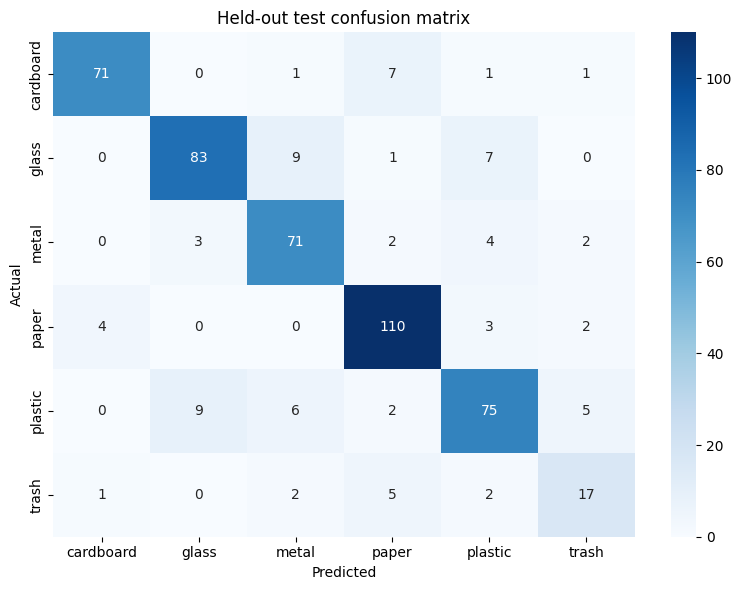

In [ ]:
test_result = evaluate_metrics(best_model, test_ds)
print(f"Accuracy:  {test_result['accuracy']:.4f}")
print(f"Precision: {test_result['precision']:.4f} (macro)")
print(f"Recall:    {test_result['recall']:.4f} (macro)")
print(f"F1:        {test_result['f1']:.4f} (macro)")
print(classification_report(test_result["y_true"], test_result["y_pred"],
                            labels=np.arange(len(CLASSES)), target_names=CLASSES,
                            zero_division=0))
cm = confusion_matrix(test_result["y_true"], test_result["y_pred"],
                      labels=np.arange(len(CLASSES)))
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Held-out test confusion matrix")
plt.tight_layout(); plt.show()

### 4.8 Save `.keras` and `.h5` model files and metrics

In [ ]:
best_model.save(MODELS/"trashnet_best_model.keras")
best_model.save(MODELS/"trashnet_best_model.h5")
metrics = {k: float(test_result[k]) for k in ["accuracy","precision","recall","f1"]}
with open(MODELS/"final_test_metrics.json","w") as f: json.dump(metrics,f,indent=2)
with open(MODELS/"experiment_results.json","w") as f:
    json.dump(comparison.to_dict(orient="records"),f,indent=2)
print("Saved both model formats and evaluation results in", MODELS)

Saved both model formats and evaluation results in /content/drive/MyDrive/TrashNet_ML_Cycle/models


### 4.9 Results interpretation from actual experiment output

In [ ]:
top = comparison.iloc[0]
bottom = comparison.iloc[-1]
print(f"Validation: {top['experiment']} has the highest macro-F1 ({top['macro_f1']:.4f}); "
      f"{bottom['experiment']} has the lowest ({bottom['macro_f1']:.4f}).")
print(f"Selected model test results: accuracy={test_result['accuracy']:.4f}, "
      f"macro precision={test_result['precision']:.4f}, macro recall={test_result['recall']:.4f}, "
      f"macro F1={test_result['f1']:.4f}.")

Validation: Experiment 2 — Fine-tuned has the highest macro-F1 (0.8498); Experiment 4 — Targeted trash augmentation has the lowest (0.7813).
Selected model test results: accuracy=0.8439, macro precision=0.8194, macro recall=0.8166, macro F1=0.8173.


## 5. Create reusable `src/model.py` and verify Drive persistence

In [ ]:
model_source = r'''
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

def build_model(num_classes=6, dropout=0.4, l2_strength=1e-4):
    """Build MobileNetV2 transfer learning classifier for 224x224 RGB images scaled to [0, 1]."""
    backbone = keras.applications.MobileNetV2(
        input_shape=(224,224,3), include_top=False, weights="imagenet"
    )
    backbone.trainable = False
    inputs = keras.Input((224,224,3))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax",
                           kernel_regularizer=regularizers.l2(l2_strength))(x)
    return keras.Model(inputs, outputs), backbone

def compile_model(model, learning_rate=1e-3):
    """Compile a multiclass image classifier using Adam and sparse categorical cross-entropy."""
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def unfreeze_top_layers(backbone, count=30):
    """Unfreeze the final backbone layers while leaving BatchNormalization layers frozen."""
    backbone.trainable = True
    for layer in backbone.layers[:-count]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
'''
(SRC/"model.py").write_text(model_source)

def predict_image(path, model=best_model):
    """Predict a single waste image and return its predicted class and confidence."""
    with Image.open(path) as im:
        arr = np.asarray(im.convert("RGB").resize((224,224)),dtype=np.float32)/255.0
    probs = model.predict(arr[None,...],verbose=0)[0]
    order = np.argsort(probs)[::-1]
    return {"predicted_class": CLASSES[int(order[0])],
            "confidence": float(probs[order[0]]),
            "probabilities": {CLASSES[int(i)]: float(probs[i]) for i in order}}
# Select the first image from the test dataset
sample = test_df.iloc[0]

# Get the model prediction
result = predict_image(sample.filepath)

# Display the actual and predicted classes
print("Actual class:   ", sample.label)
print("Predicted class:", result["predicted_class"])
print("Confidence:     ", f"{result['confidence']:.2%}")

print("\nClass probabilities:")
for class_name, probability in result["probabilities"].items():
    print(f"{class_name}: {probability:.2%}")

Actual class:    plastic
Predicted class: plastic
Confidence:      97.81%

Class probabilities:
plastic: 97.81%
metal: 1.56%
trash: 0.27%
glass: 0.19%
paper: 0.17%
cardboard: 0.00%


## 6. Run summary and persistent outputs

In [ ]:
summary = {
    "raw_zip": str(RAW_ZIP),
    "readable_images": int(len(df)),
    "corrupted_images": int(len(corrupt_df)),
    "train_images": int(len(train_df)),
    "test_images": int(len(test_df)),
    "fit_images": int(len(fit_df)),
    "validation_images": int(len(validation_df)),
    "classes": CLASSES,
    "fit_images": int(len(fit_df)),   "validation_images": int(len(validation_df)),   "selected_experiment": best_name,
    "test_metrics": metrics
}
with open(REPORTS/"run_summary.json","w") as f: json.dump(summary,f,indent=2)
print("Files saved in Google Drive:")
for p in sorted(PROJECT.rglob("*")):
    if p.is_file(): print(p.relative_to(PROJECT), f"{p.stat().st_size:,} bytes")

Streaming output truncated to the last 5000 lines.
data/extracted/dataset-resized/cardboard/cardboard165.jpg 20,387 bytes
data/extracted/dataset-resized/cardboard/cardboard166.jpg 27,876 bytes
data/extracted/dataset-resized/cardboard/cardboard167.jpg 19,498 bytes
data/extracted/dataset-resized/cardboard/cardboard168.jpg 15,681 bytes
data/extracted/dataset-resized/cardboard/cardboard169.jpg 12,535 bytes
data/extracted/dataset-resized/cardboard/cardboard17.jpg 28,358 bytes
data/extracted/dataset-resized/cardboard/cardboard170.jpg 8,912 bytes
data/extracted/dataset-resized/cardboard/cardboard171.jpg 8,496 bytes
data/extracted/dataset-resized/cardboard/cardboard172.jpg 11,712 bytes
data/extracted/dataset-resized/cardboard/cardboard173.jpg 9,813 bytes
data/extracted/dataset-resized/cardboard/cardboard174.jpg 16,195 bytes
data/extracted/dataset-resized/cardboard/cardboard175.jpg 23,224 bytes
data/extracted/dataset-resized/cardboard/cardboard176.jpg 29,480 bytes
data/extracted/dataset-resized

## Checklist coverage

- [x] Mount Drive and load `data/trashnet_raw.zip`
- [x] Stratified 80/20 split and CSV manifests
- [x] Class counts, imbalance, image sizes, corrupted files
- [x] Four EDA visualizations with output-based interpretations
- [x] Exclude unreadable images; save `models/class_names.json`
- [x] Class weights; 224×224; training-only augmentation; [0,1] scaling; validation split
- [x] Create `src/preprocessing.py` and `src/model.py`; functions include docstrings
- [x] Three experiments and validation comparison
- [x] Two-stage MobileNetV2; early stopping, LR scheduler, dropout, L2
- [x] Accuracy, macro precision, macro recall, macro F1, classification report and confusion matrix
- [x] Save `.keras` and `.h5` model files in Drive

**Important:** the notebook creates `data/train/` and `data/test/` directories, and saves the split manifests as `data/train.csv` and `data/test.csv`. The original images remain in the extracted source directory and the CSV files point to them; this avoids duplicating image files in Drive. If your submission strictly requires copied image files inside `data/train/` and `data/test/`, we can add a copy step after checking your available Drive storage.